# Stories Café: Weather and Seasons, by Branch

**Question:** does the weather (temperature, rain, wind) or the season (winter, spring, summer) change how much people buy, what they buy (iced vs hot drinks), and how they buy (dine-in vs takeaway, time of day), at each branch?

**Weather data:** daily weather for Jan 1 to Jun 30, 2026 from the [Open-Meteo historical weather archive](https://open-meteo.com/) (free, no account needed). It's modelled weather for a point on the map, built from weather-station, satellite and radar observations, with the daily maximum and minimum temperature, total rain and maximum wind speed. The files are in `data/external/`, and the exact download link for each is in the first code cell.

**Where the branches are:** the dataset doesn't say. The branch names suggest the North and Mount Lebanon (Jabal), so this notebook treats **all three branches as being in the North** and uses **Batroun** weather for them. Section 7 then repeats the key tests with **Jabal weather (Broummana, about 630 m up)** and with the Beirut weather the team used earlier, in case some branches are actually in the mountains.

| Location | Region | Used for |
|---|---|---|
| Batroun | North (coast) | All three branches (main analysis) |
| Broummana | Mount Lebanon / Jabal (about 630 m) | Check in section 7 |
| Beirut | Beirut (coast) | Check in section 7 (the team's earlier weather data) |

**Seasons** (meteorological, set in the first code cell):

| Season | Dates | Days |
|---|---|---|
| Winter | Jan 1 to Feb 28 | 59 |
| Spring | Mar 1 to May 31 | 92 |
| Summer | Jun 1 to Jun 30 | 30 |

The data ends on Jun 30, so "summer" is only its first month.

**Sections**
1. Setup
2. What the weather was like in each season, North vs Jabal
3. Method: separating weather from growth
4. Harbour
5. Garden
6. Uptown
7. Check: what if the branches are in the Jabal (or Beirut)?
8. The three branches side by side
9. Conclusion

Each branch section has the same five parts: (a) orders by season, (b) day-to-day weather vs demand, (c) rainy vs dry days, (d) iced vs hot drinks, (e) how people buy.

## 1. Setup

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from IPython.display import display

# --- Season boundaries (month numbers) and the rainy-day threshold. Change and re-run. ---
SEASON_OF_MONTH = {1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring", 6: "Summer"}
SEASONS = ["Winter", "Spring", "Summer"]
RAINY_MM = 1.0  # a day with at least 1 mm of rain counts as rainy

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
# Seasons are ordered in time, so they use one hue light to dark
SEASON_COLORS = dict(zip(SEASONS, ["#86b6ef", "#256abf", "#0d366b"]))
ACCENT, WARM, MUTED = "#2a78d6", "#eb6834", "#b9b8b3"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "lines.linewidth": 2,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
R, GP = "Line Revenue (USD)", "Line Gross Profit (USD)"

# --- Weather locations (Open-Meteo archive). Download link pattern:
# https://archive-api.open-meteo.com/v1/archive?latitude=<lat>&longitude=<lon>&start_date=2026-01-01&end_date=2026-06-30
#   &daily=temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max&timezone=Asia%2FBeirut
LOCATIONS = {
    "North (Batroun)": ("../data/external/batroun_weather_2026H1.json", 34.2553, 35.6581),
    "Jabal (Broummana)": ("../data/external/broummana_weather_2026H1.json", 33.8828, 35.6206),
    "Beirut": ("../data/external/beirut_weather_2026H1.json", 33.89, 35.50),
}
MAIN_LOCATION = "North (Batroun)"  # weather used for all three branches in sections 2-6 and 8
# Locations get their own hues so they are never confused with the branch colors (blue, orange, green)
LOCATION_COLORS = {"North (Batroun)": "#6250d6", "Jabal (Broummana)": "#e87ba4", "Beirut": "#9a9993"}


def load_weather(path):
    w = pd.DataFrame(json.loads(open(path).read())["daily"])
    w["date"] = pd.to_datetime(w.pop("time"))
    w = w.set_index("date").rename(columns={
        "temperature_2m_max": "max_temp_c", "temperature_2m_min": "min_temp_c",
        "precipitation_sum": "rain_mm", "wind_speed_10m_max": "max_wind_kmh"})
    w["season"] = pd.Categorical(w.index.month.map(SEASON_OF_MONTH), SEASONS, ordered=True)
    w["rainy"] = w["rain_mm"] >= RAINY_MM
    return w


weathers = {name: load_weather(path) for name, (path, lat, lon) in LOCATIONS.items()}
weather = weathers[MAIN_LOCATION]

df = pd.read_csv("../data/stories_transactions.csv").drop_duplicates()  # 132 duplicate lines, as in 01_eda
df["Date"] = pd.to_datetime(df["Date"])
df["hour"] = pd.to_datetime(df["Time"], format="%H:%M:%S").dt.hour
df = df.join(weather[["season", "rainy", "max_temp_c"]], on="Date")

# Drinks served cold vs hot (food is left out of this split)
ICED_PRODUCTS = {"Iced Matcha", "Strawberry Matcha"}
HOT_PRODUCTS = {"Classic Matcha", "Chai Latte", "Mint Tea", "English Breakfast Tea"}
df["serve"] = np.select(
    [df["Category"].isin(["Cold Coffee", "Cold Drinks"]) | df["Product"].isin(ICED_PRODUCTS),
     df["Category"].eq("Hot Coffee") | df["Product"].isin(HOT_PRODUCTS)],
    ["Iced drink", "Hot drink"], "Food")
df["iced_units"] = df["serve"].eq("Iced drink") * df["Quantity"]

orders = df.groupby("Transaction ID").agg(
    date=("Date", "first"), hour=("hour", "first"), branch=("Branch", "first"),
    order_type=("Order Type", "first"), revenue=(R, "sum"), items=("Quantity", "sum"))
orders = orders.join(weather[["season", "rainy", "max_temp_c", "rain_mm"]], on="date")
weather.head()

,max_temp_c,min_temp_c,rain_mm,max_wind_kmh,season,rainy
date,,,,,,
2026-01-01,16.1,13.4,92.3,40.6,Winter,True
2026-01-02,15.0,10.6,1.1,13.1,Winter,True
2026-01-03,14.5,10.3,0.0,13.4,Winter,False
2026-01-04,16.5,11.0,0.0,13.2,Winter,False
2026-01-05,18.5,13.2,0.0,14.6,Winter,False


## 2. What the weather was like in each season, North vs Jabal

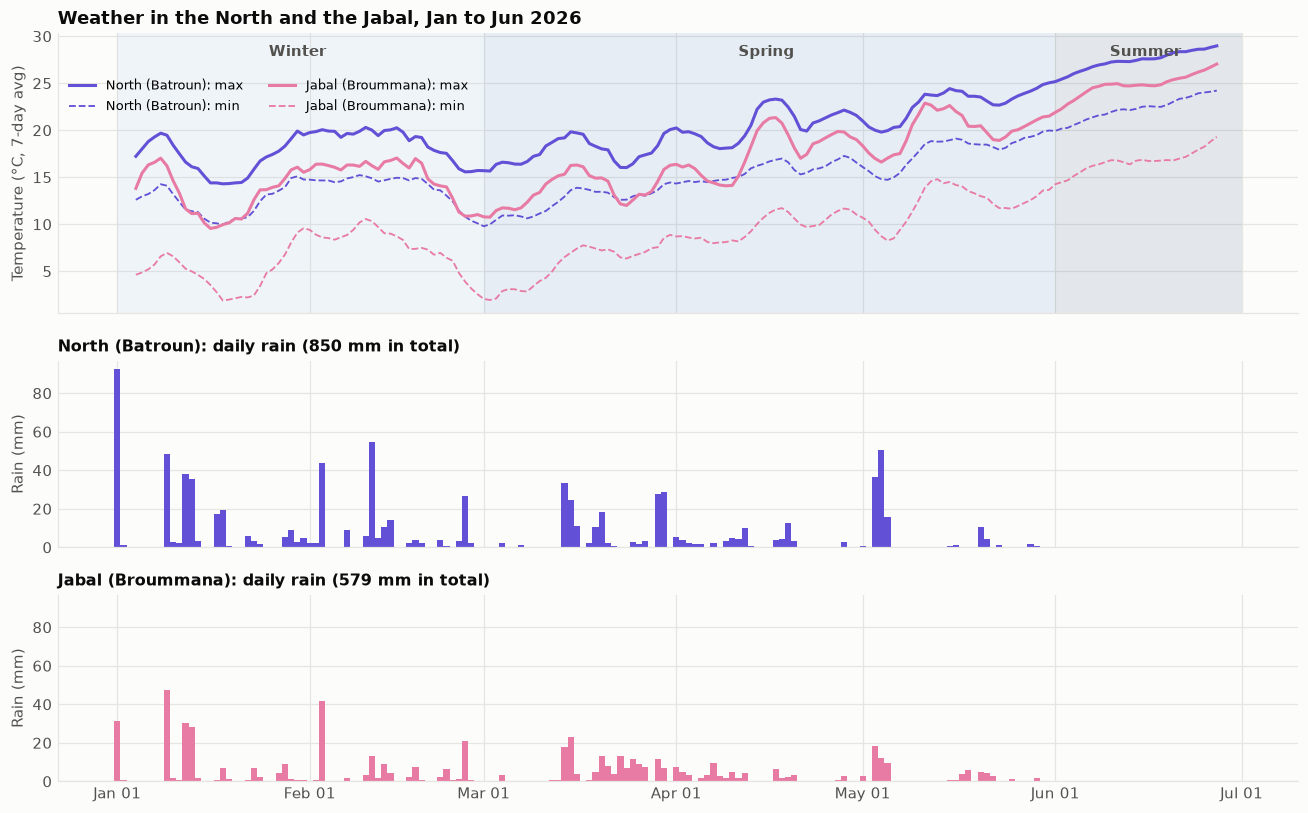

In [2]:
season_weather = pd.concat({
    name: w.groupby("season", observed=True).agg(
        avg_max_temp_c=("max_temp_c", "mean"), avg_min_temp_c=("min_temp_c", "mean"),
        total_rain_mm=("rain_mm", "sum"), rainy_days=("rainy", "sum"), avg_max_wind_kmh=("max_wind_kmh", "mean"))
    for name, w in weathers.items()}, names=["location", "season"])

shown = ["North (Batroun)", "Jabal (Broummana)"]
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.5, 1, 1]})
ax = axes[0]
for s in SEASONS:
    d = weather[weather["season"] == s]
    ax.axvspan(d.index.min(), d.index.max() + pd.Timedelta(days=1), color=SEASON_COLORS[s], alpha=0.10, lw=0)
    ax.text(d.index.min() + (d.index.max() - d.index.min()) / 2, 0.96, s, transform=ax.get_xaxis_transform(),
            ha="center", va="top", color=INK2, fontweight="bold")
for name in shown:
    w = weathers[name]
    ax.plot(w.index, w["max_temp_c"].rolling(7, center=True).mean(), color=LOCATION_COLORS[name],
            label=f"{name}: max")
    ax.plot(w.index, w["min_temp_c"].rolling(7, center=True).mean(), color=LOCATION_COLORS[name], lw=1.2, ls="--",
            label=f"{name}: min")
ax.set_ylabel("Temperature (°C, 7-day avg)")
ax.set_title("Weather in the North and the Jabal, Jan to Jun 2026")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.88), ncols=2, fontsize=8.5)
for ax, name in zip(axes[1:], shown):
    w = weathers[name]
    ax.bar(w.index, w["rain_mm"], color=LOCATION_COLORS[name], width=1)
    ax.set_ylabel("Rain (mm)")
    ax.set_title(f"{name}: daily rain ({w['rain_mm'].sum():,.0f} mm in total)", fontsize=10.5)
axes[2].set_ylim(axes[1].get_ylim())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.tight_layout()
plt.show()

season_weather.style.format("{:.1f}").format("{:.0f}", subset=["rainy_days", "total_rain_mm"])

**Takeaway:** a real seasonal swing in both places.
- **North (Batroun):** winter averaged about 18°C (max) with 33 rainy days and 487 mm of rain; spring about 20°C with 37 rainy days; June about 28°C and dry. It's the wettest and windiest of the three locations (850 mm over the six months, vs about 640 mm in Beirut).
- **Jabal (Broummana):** about 2.5-4°C colder in the daytime and up to 7°C colder at night (winter nights around 6°C vs 13°C in Batroun). Winter max about 14°C, spring 17°C, June 25°C. A similar number of rainy days (26 in winter, 42 in spring) but less rain in total (about 580 mm).

## 3. Method: separating weather from growth

Orders grew steadily all six months (about +50%), so summer would look busier than winter even if the weather didn't matter. Tuesdays are also much busier than other days.

So for each branch we fit daily orders with a **growth trend + weekday effect** (no weather) and look at what's left over: the **"orders vs expected"**. If a season or the weather matters, that leftover should be consistently positive or negative in that season, or move with temperature or rain.

The functions below draw the same five parts for any branch.

In [3]:
daily = orders.groupby(["date", "branch"]).size().unstack()[BRANCHES]
daily["All branches"] = daily.sum(axis=1)


def leftover(daily_orders):
    """Log orders minus a trend + weekday fit: the share of demand the calendar does not explain."""
    t = (daily_orders.index - daily_orders.index[0]).days.to_numpy()
    dow = pd.get_dummies(daily_orders.index.dayofweek, drop_first=True).to_numpy(float)
    X = np.column_stack([np.ones(len(t)), t, dow])
    y = np.log(daily_orders.to_numpy())
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    return pd.Series(y - X @ beta, index=daily_orders.index)


resid = pd.DataFrame({name: leftover(daily[name]) for name in ["All branches", *BRANCHES]}).join(weather)
vs_expected = np.exp(resid[["All branches", *BRANCHES]]) - 1  # leftover as "+3%" / "-2%"


def season_effect(b):
    """(a) Raw orders per day by season next to the season effect after removing growth and weekday."""
    raw = daily[b].groupby(weather["season"], observed=True).mean()
    adj = np.exp(resid.groupby("season", observed=True)[b].mean()) - 1
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    colors = [SEASON_COLORS[s] for s in SEASONS]
    axes[0].bar(SEASONS, raw.values, color=colors, width=0.6)
    for i, v in enumerate(raw.values):
        axes[0].text(i, v + 1, f"{v:.0f}", ha="center", color=INK2)
    axes[0].set_ylabel("Orders per day")
    axes[0].set_title(f"{b}: raw orders per day")
    axes[1].bar(SEASONS, adj.values, color=colors, width=0.6)
    for i, v in enumerate(adj.values):
        axes[1].text(i, v + (0.002 if v >= 0 else -0.002), f"{v:+.1%}", ha="center",
                     va="bottom" if v >= 0 else "top", color=INK2)
    axes[1].axhline(0, color=INK2, lw=1)
    axes[1].yaxis.set_major_formatter(pct)
    axes[1].set_ylim(-0.06, 0.06)
    axes[1].set_title(f"{b}: after removing growth and weekday")
    for ax in axes:
        ax.grid(axis="x", visible=False)
    plt.tight_layout()
    plt.show()


def weather_scatter(b):
    """(b) Each day's orders vs expected against temperature, rain and wind."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.9), sharey=True)
    y = vs_expected[b]
    for ax, col, label in [(axes[0], "max_temp_c", "Max temperature (°C)"), (axes[1], "rain_mm", "Rain (mm)"),
                           (axes[2], "max_wind_kmh", "Max wind (km/h)")]:
        for s in SEASONS:
            m = resid["season"] == s
            ax.scatter(resid.loc[m, col], y[m], s=16, color=SEASON_COLORS[s], alpha=0.85, label=s,
                       edgecolors=SURFACE, linewidths=0.5)
        slope, icpt = np.polyfit(resid[col], y, 1)
        xs = np.linspace(resid[col].min(), resid[col].max(), 20)
        ax.plot(xs, icpt + slope * xs, color=INK2, lw=1.2, ls="--")
        ax.axhline(0, color=GRID, lw=1)
        ax.set_xlabel(label)
        ax.set_title(f"corr. {resid[b].corr(resid[col]):+.2f}")
        ax.yaxis.set_major_formatter(pct)
    axes[0].set_ylabel("Orders vs expected")
    axes[0].legend(loc="upper left", fontsize=8.5)
    fig.suptitle(f"{b}: does the weather move demand? Each dot is one day", x=0.01, ha="left",
                 fontweight="bold", fontsize=12)
    plt.tight_layout()
    plt.show()


def rain_table(b):
    """(c) Orders on rainy vs dry days, overall and within winter and spring."""
    def lift(mask):
        return np.exp(resid.loc[mask & resid["rainy"], b].mean() - resid.loc[mask & ~resid["rainy"], b].mean()) - 1
    all_days = pd.Series(True, index=resid.index)
    t = pd.DataFrame({
        "rainy days": [resid["rainy"].sum(), (resid["rainy"] & (resid["season"] == "Winter")).sum(),
                       (resid["rainy"] & (resid["season"] == "Spring")).sum()],
        "orders, rainy vs dry": [lift(all_days), lift(resid["season"] == "Winter"), lift(resid["season"] == "Spring")],
    }, index=["Whole period", "Winter", "Spring"])
    return t.style.format({"rainy days": "{:.0f}", "orders, rainy vs dry": "{:+.1%}"}).set_caption(
        f"{b}: rainy (>= {RAINY_MM:g} mm) vs dry days, after growth and weekday (summer had no rain)")


def iced_drinks(b):
    """(d) Iced share of drinks against daily temperature and by season."""
    d = df[(df["Branch"] == b) & (df["serve"] != "Food")]
    day = d.groupby("Date")[["iced_units", "Quantity"]].sum()
    day = (day["iced_units"] / day["Quantity"]).rename("iced_share").to_frame().join(weather["max_temp_c"])
    season = d.groupby("season", observed=True)[["iced_units", "Quantity"]].sum()
    season = season["iced_units"] / season["Quantity"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1.4, 1]})
    ax = axes[0]
    ax.scatter(day["max_temp_c"], day["iced_share"], s=14, color=BRANCH_COLORS[b], alpha=0.7)
    slope, icpt = np.polyfit(day["max_temp_c"], day["iced_share"], 1)
    xs = np.linspace(day["max_temp_c"].min(), day["max_temp_c"].max(), 20)
    ax.plot(xs, icpt + slope * xs, color=INK, lw=1.5, ls="--")
    ax.yaxis.set_major_formatter(pct)
    ax.set_ylim(0.3, 0.85)
    ax.set_xlabel("Max temperature (°C)")
    ax.set_ylabel("Iced share of drinks")
    ax.set_title(f"{b}: iced share vs temperature (corr. {day['iced_share'].corr(day['max_temp_c']):+.2f})")
    ax = axes[1]
    ax.bar(SEASONS, season.values, color=[SEASON_COLORS[s] for s in SEASONS], width=0.6)
    for i, v in enumerate(season.values):
        ax.text(i, v + 0.01, f"{v:.0%}", ha="center", color=INK2)
    ax.yaxis.set_major_formatter(pct)
    ax.set_ylim(0, 0.85)
    ax.set_title(f"{b}: iced share by season")
    ax.grid(axis="x", visible=False)
    plt.tight_layout()
    plt.show()


def how_they_buy(b):
    """(e) Hour profile by season, plus takeaway / evening share / order value by season and on rainy days."""
    o = orders[orders["branch"] == b]
    mix = pd.crosstab(o["hour"], o["season"], normalize="columns")[SEASONS]
    fig, ax = plt.subplots(figsize=(10, 3.6))
    for s in SEASONS:
        ax.plot(mix.index, mix[s], color=SEASON_COLORS[s], marker="o", ms=3, label=s)
    ax.set_xticks(mix.index[::2])
    ax.set_xlabel("Hour of day")
    ax.yaxis.set_major_formatter(pct)
    ax.set_ylabel("Share of the season's orders")
    ax.set_title(f"{b}: when people order, by season")
    ax.legend(loc="upper left")
    plt.show()
    groups = {**{s: o[o["season"] == s] for s in SEASONS}, "Dry days": o[~o["rainy"]], "Rainy days": o[o["rainy"]]}
    t = pd.DataFrame({name: {"takeaway share": (g["order_type"] == "Takeaway").mean(),
                             "evening share (18:00+)": (g["hour"] >= 18).mean(),
                             "average order value": g["revenue"].mean()} for name, g in groups.items()}).T
    return t.style.format({"takeaway share": "{:.1%}", "evening share (18:00+)": "{:.1%}",
                           "average order value": "${:.2f}"}).set_caption(f"{b}: how people buy")

## 4. Harbour

### 4a. Orders by season

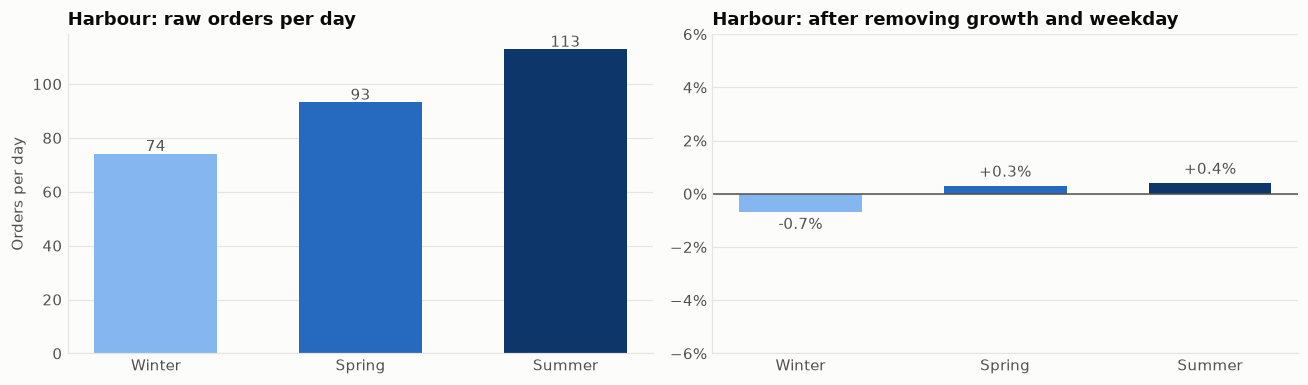

In [4]:
season_effect("Harbour")

### 4b. Day-to-day weather vs demand

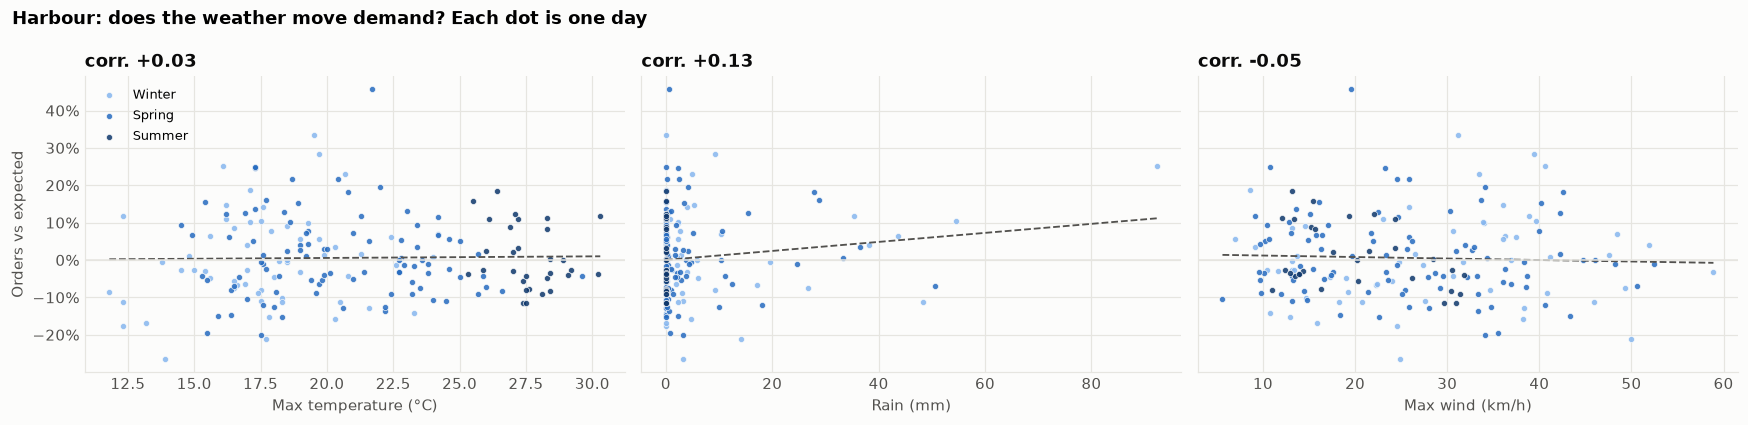

In [5]:
weather_scatter("Harbour")

### 4c. Rainy vs dry days

In [6]:
rain_table("Harbour")

,rainy days,"orders, rainy vs dry"
Whole period,70,+1.0%
Winter,33,+2.1%
Spring,37,+1.1%


### 4d. Iced vs hot drinks

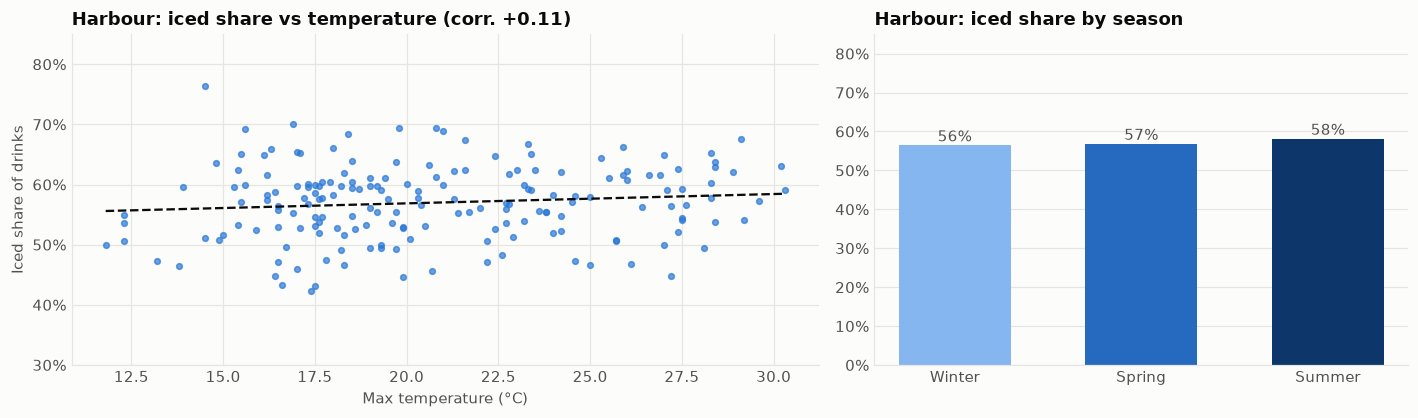

In [7]:
iced_drinks("Harbour")

### 4e. How people buy

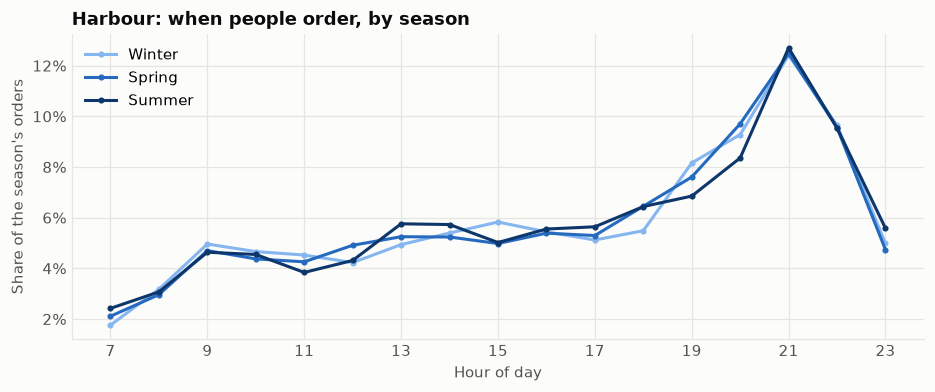

,takeaway share,evening share (18:00+),average order value
Winter,41.6%,50.0%,$9.16
Spring,40.9%,50.5%,$9.16
Summer,40.6%,49.5%,$9.30
Dry days,40.8%,49.6%,$9.19
Rainy days,41.4%,51.2%,$9.18


In [8]:
how_they_buy("Harbour")

**Harbour takeaway**
- **(a) Seasons:** raw orders rise from 74 a day in winter to 113 in June, but after removing growth and weekday every season is **within 1%** of expected (winter -0.7%, spring +0.3%, summer +0.4%).
- **(b) Weather (North):** correlations with temperature (+0.03), rain (+0.13) and wind (-0.05) are all small. Rain is the largest, and it points the "wrong" way for a café: slightly *more* orders on wetter days.
- **(c) Rain:** rainy days are about **+1%** vs dry days overall (winter +2%, spring +1%).
- **(d) Iced drinks:** about **57-58% of drinks in every season**. Harbour has the strongest link to temperature of the three branches (about +0.1), but it's still weak: June's iced share (58%) is barely above January's (56%).
- **(e) How people buy:** takeaway (about 41%), evening share (about 50%) and order value ($9.16 to $9.30) barely change across seasons or on rainy days.

**Verdict: no weather effect at Harbour.**

## 5. Garden

### 5a. Orders by season

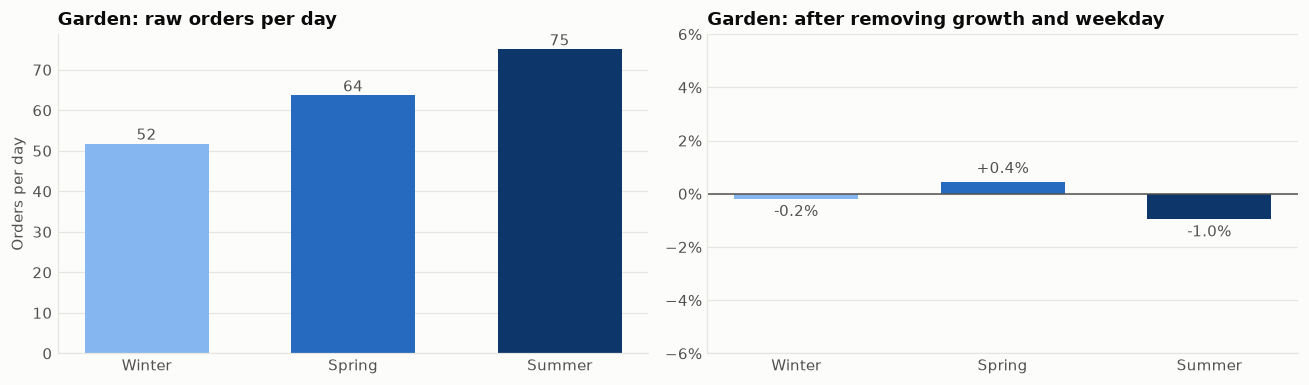

In [9]:
season_effect("Garden")

### 5b. Day-to-day weather vs demand

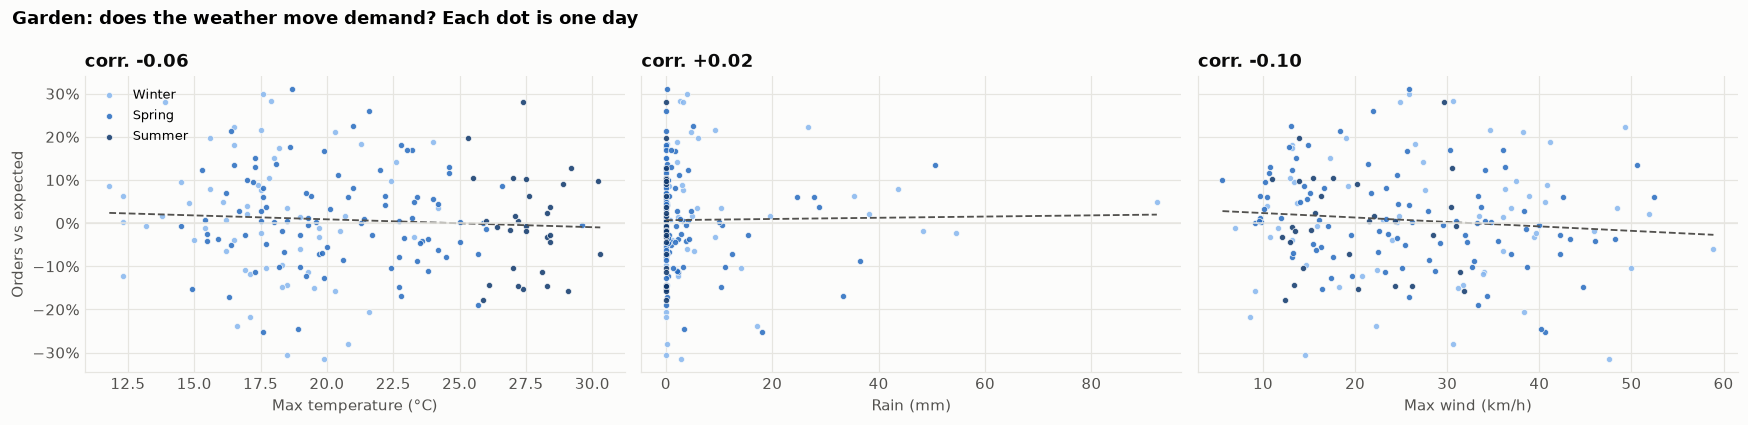

In [10]:
weather_scatter("Garden")

### 5c. Rainy vs dry days

In [11]:
rain_table("Garden")

,rainy days,"orders, rainy vs dry"
Whole period,70,+0.1%
Winter,33,+6.2%
Spring,37,-4.1%


### 5d. Iced vs hot drinks

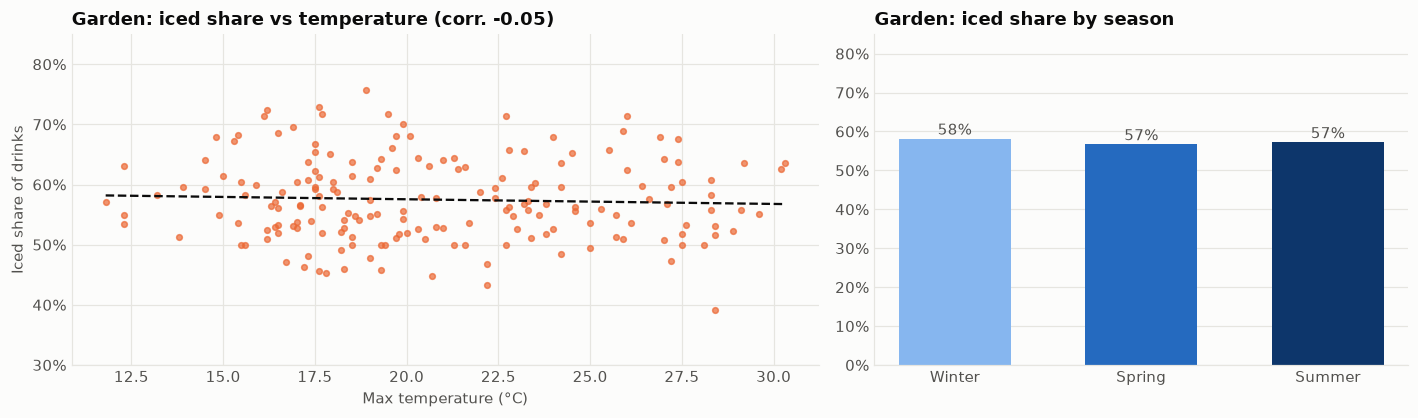

In [12]:
iced_drinks("Garden")

### 5e. How people buy

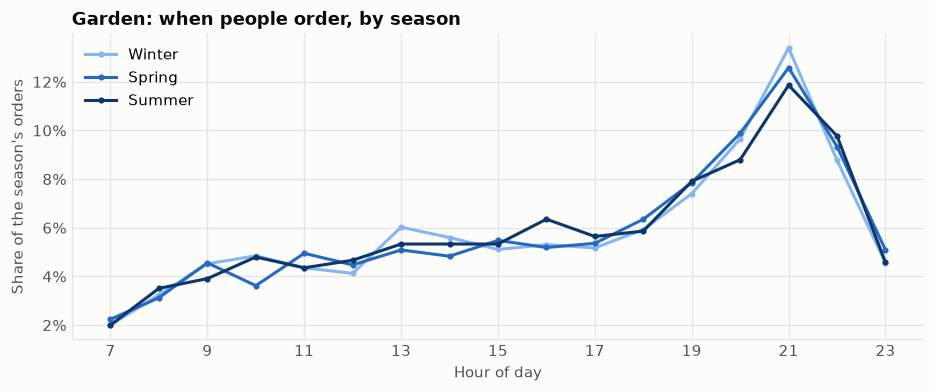

,takeaway share,evening share (18:00+),average order value
Winter,40.9%,49.7%,$8.92
Spring,40.9%,51.1%,$8.91
Summer,43.0%,48.8%,$8.92
Dry days,41.3%,50.1%,$8.90
Rainy days,41.4%,50.5%,$8.95


In [13]:
how_they_buy("Garden")

**Garden takeaway**
- **(a) Seasons:** raw orders rise from 52 a day in winter to 75 in June. After removing growth and weekday: winter -0.2%, spring +0.4%, summer -1.0%. All **within about 1%**.
- **(b) Weather (North):** temperature -0.06, rain +0.02, wind -0.10. Wind is the strongest of the three, and still weak: windier days are very slightly quieter.
- **(c) Rain:** about **0%** vs dry days overall. Winter (+6%) and spring (-4%) point in opposite directions, so there's no consistent rain effect.
- **(d) Iced drinks:** about **57-58% in every season**, and very slightly *down* with temperature (-0.06). Garden's iced share was actually highest in January (59%).
- **(e) How people buy:** takeaway rises slightly in June (43% vs 41%), within normal variation. Evening share and order value ($8.91 to $8.92) are flat.

**Verdict: no weather effect at Garden.**

## 6. Uptown

### 6a. Orders by season

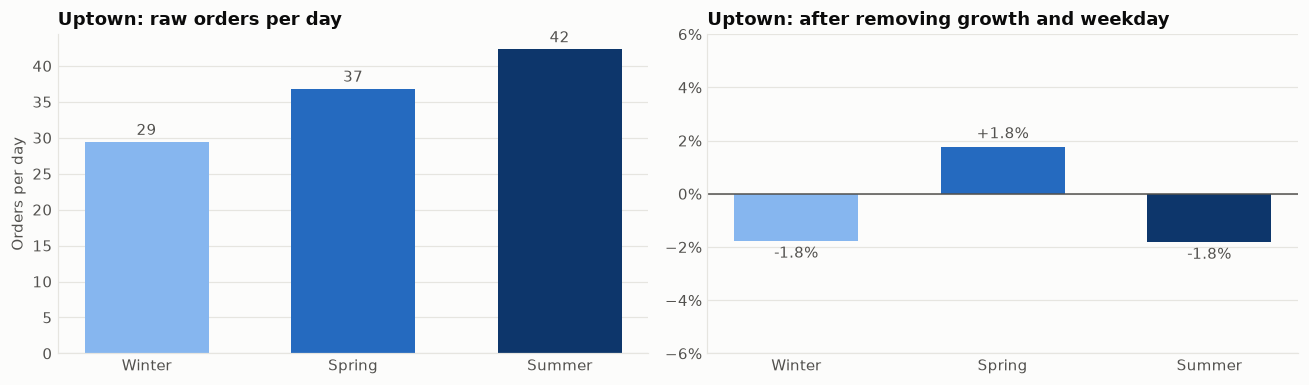

In [14]:
season_effect("Uptown")

### 6b. Day-to-day weather vs demand

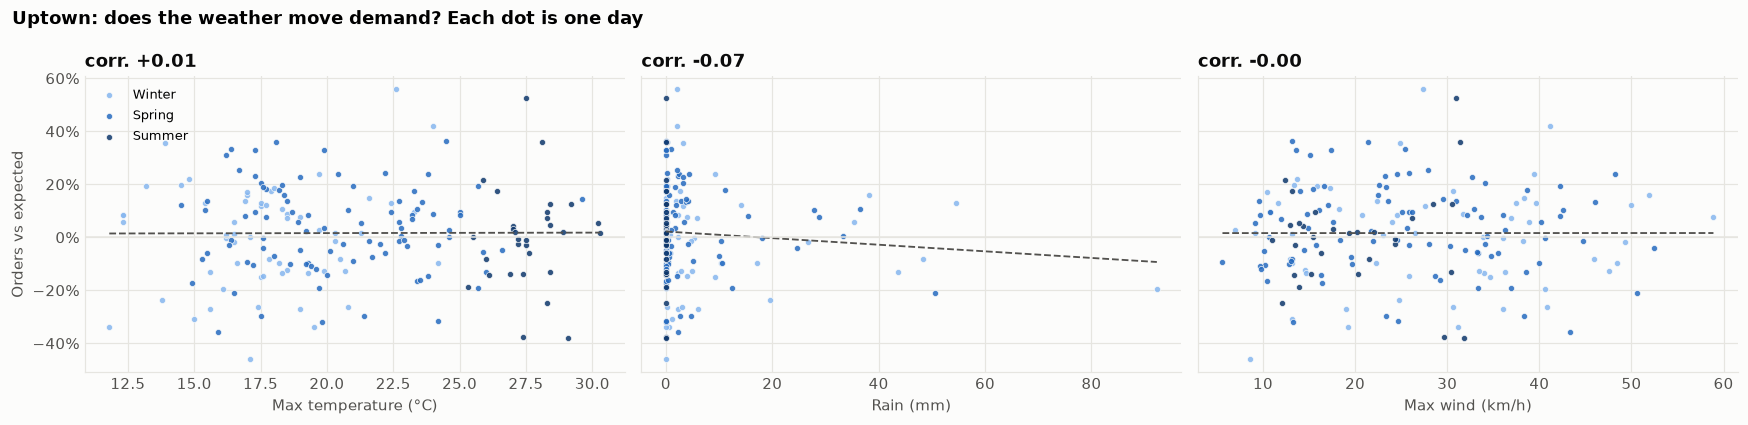

In [15]:
weather_scatter("Uptown")

### 6c. Rainy vs dry days

In [16]:
rain_table("Uptown")

,rainy days,"orders, rainy vs dry"
Whole period,70,+0.9%
Winter,33,-0.1%
Spring,37,+1.6%


### 6d. Iced vs hot drinks

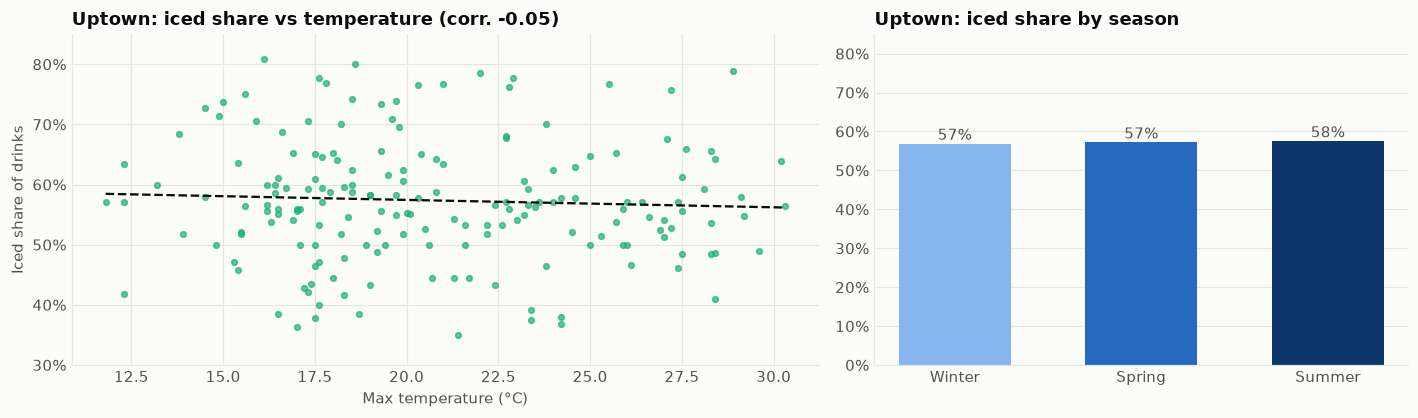

In [17]:
iced_drinks("Uptown")

### 6e. How people buy

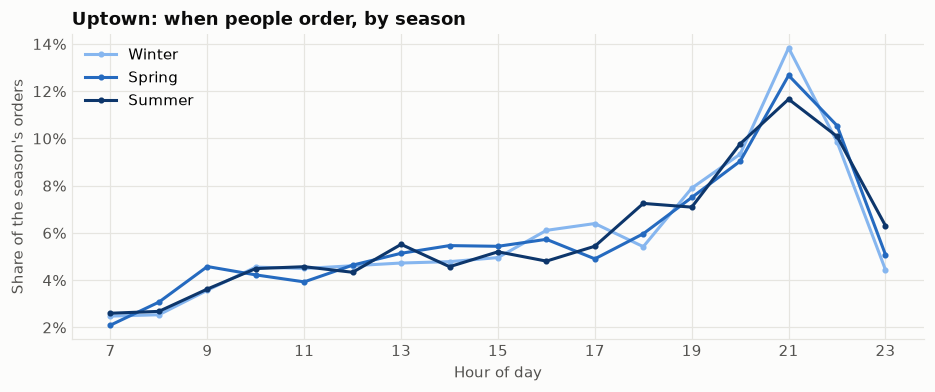

,takeaway share,evening share (18:00+),average order value
Winter,39.3%,50.8%,$8.87
Spring,39.6%,50.8%,$8.64
Summer,40.8%,52.2%,$8.59
Dry days,39.7%,50.5%,$8.63
Rainy days,39.8%,52.0%,$8.82


In [18]:
how_they_buy("Uptown")

**Uptown takeaway**
- **(a) Seasons:** raw orders rise from 29 a day in winter to 42 in June. After removing growth and weekday: winter -1.8%, spring +1.8%, summer -1.8%. Still **within 2%**; Uptown moves around more because it's the smallest branch.
- **(b) Weather (North):** temperature +0.01, rain -0.07, wind 0.00. No relationship.
- **(c) Rain:** about **+1%** vs dry days overall (winter 0%, spring +2%). With Beirut weather, Uptown showed a -7% dip on rainy winter days; with the North's rain that dip disappears, so it came from which days happened to rain in Beirut.
- **(d) Iced drinks:** about **57-58% in every season**, slightly *down* with temperature (-0.07).
- **(e) How people buy:** takeaway (39-41%), evening share (about 51%) and order value are similar across seasons. Order value drifts down from $8.87 in winter to $8.59 in June, but the same drift appears in other notebooks and isn't tied to the weather.

**Verdict: no weather effect at Uptown.**

## 7. Check: what if the branches are in the Jabal (or Beirut)?

The mountains are colder and get their rain on different days from the coast, so if a branch is really in the Jabal, the North weather could hide an effect. Here we repeat the key tests for every branch with each location's weather.

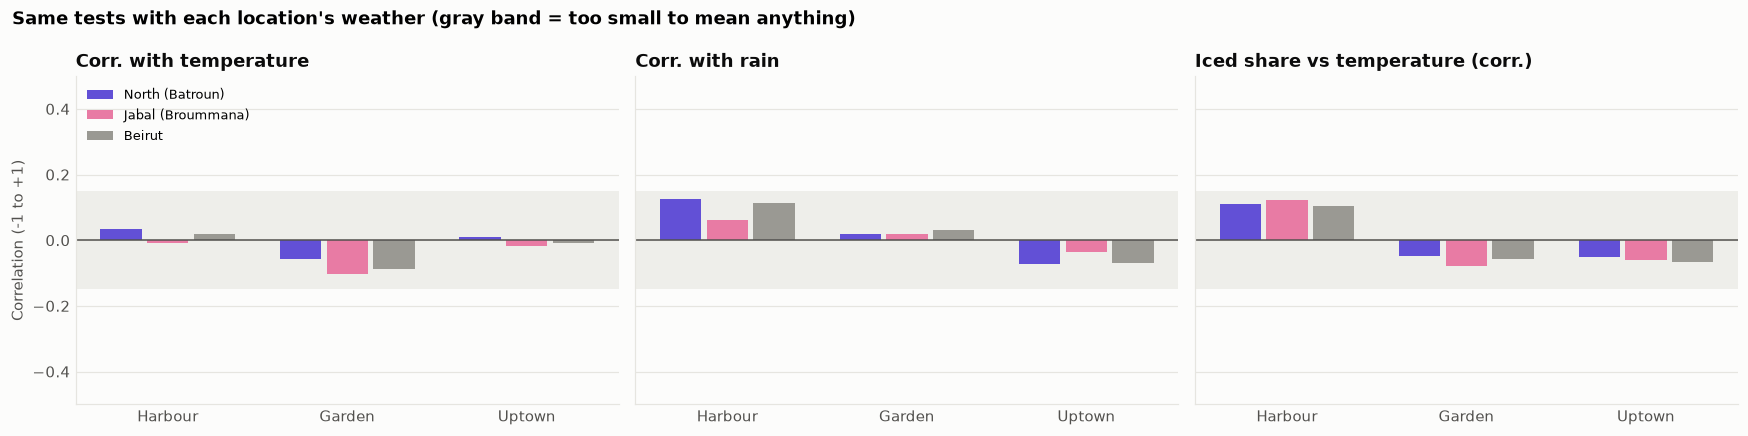

In [19]:
rows = []
for loc, w in weathers.items():
    r = resid[["All branches", *BRANCHES]].join(w)
    for b in BRANCHES:
        d = df[(df["Branch"] == b) & (df["serve"] != "Food")].groupby("Date")[["iced_units", "Quantity"]].sum()
        iced_share = (d["iced_units"] / d["Quantity"]).rename("iced").to_frame().join(w["max_temp_c"])
        rows.append({
            "location": loc, "branch": b,
            "corr. with temperature": r[b].corr(r["max_temp_c"]),
            "corr. with rain": r[b].corr(r["rain_mm"]),
            "corr. with wind": r[b].corr(r["max_wind_kmh"]),
            "rainy vs dry days": np.exp(r.loc[r["rainy"], b].mean() - r.loc[~r["rainy"], b].mean()) - 1,
            "iced share vs temperature (corr.)": iced_share["iced"].corr(iced_share["max_temp_c"]),
        })
check = pd.DataFrame(rows).set_index(["branch", "location"]).loc[BRANCHES]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
x = np.arange(len(BRANCHES))
bw = 0.26
for ax, col in zip(axes, ["corr. with temperature", "corr. with rain", "iced share vs temperature (corr.)"]):
    for i, loc in enumerate(LOCATIONS):
        vals = check.xs(loc, level="location")[col].reindex(BRANCHES).values
        ax.bar(x + (i - 1) * bw, vals, width=bw - 0.03, color=LOCATION_COLORS[loc], label=loc)
    ax.axhspan(-0.15, 0.15, color=GRID, alpha=0.6, lw=0, zorder=0)
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xticks(x, BRANCHES)
    ax.set_ylim(-0.5, 0.5)
    ax.set_title(col[0].upper() + col[1:])
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Correlation (-1 to +1)")
axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("Same tests with each location's weather (gray band = too small to mean anything)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

check.style.format("{:+.2f}").format("{:+.1%}", subset=["rainy vs dry days"])

**Takeaway:** it doesn't matter which weather we use. With North, Jabal or Beirut weather, **every correlation stays between -0.12 and +0.13** (inside the gray band), and **rainy days are within about 3% of dry days at every branch**. The iced share of drinks doesn't follow the temperature anywhere, even with the mountains' colder winters. So the conclusion doesn't depend on where the branches are.

## 8. The three branches side by side

In [20]:
season_adj = (np.exp(resid.groupby("season", observed=True)[BRANCHES].mean()) - 1).T
season_adj.columns = [f"{s}: orders vs expected" for s in SEASONS]
corr = pd.DataFrame({f"corr. with {label}": [resid[b].corr(resid[col]) for b in BRANCHES]
                     for col, label in [("max_temp_c", "temperature"), ("rain_mm", "rain"), ("max_wind_kmh", "wind")]},
                    index=BRANCHES)
rain = pd.Series({b: np.exp(resid.loc[resid["rainy"], b].mean() - resid.loc[~resid["rainy"], b].mean()) - 1
                  for b in BRANCHES}, name="rainy vs dry days")
iced = df[df["serve"] != "Food"].groupby(["Branch", "season"], observed=True)[["iced_units", "Quantity"]].sum()
iced = (iced["iced_units"] / iced["Quantity"]).unstack()[SEASONS].loc[BRANCHES]
iced.columns = [f"{s}: iced share" for s in SEASONS]

side = season_adj.join(corr).join(rain).join(iced)
fmt = {c: "{:+.1%}" for c in season_adj.columns} | {c: "{:+.2f}" for c in corr.columns} | \
      {"rainy vs dry days": "{:+.1%}"} | {c: "{:.0%}" for c in iced.columns}
side.style.format(fmt)

,Winter: orders vs expected,Spring: orders vs expected,Summer: orders vs expected,corr. with temperature,corr. with rain,corr. with wind,rainy vs dry days,Winter: iced share,Spring: iced share,Summer: iced share
Harbour,-0.7%,+0.3%,+0.4%,+0.03,+0.13,-0.05,+1.0%,56%,57%,58%
Garden,-0.2%,+0.4%,-1.0%,-0.06,+0.02,-0.10,+0.1%,58%,57%,57%
Uptown,-1.8%,+1.8%,-1.8%,+0.01,-0.07,-0.00,+0.9%,57%,57%,58%


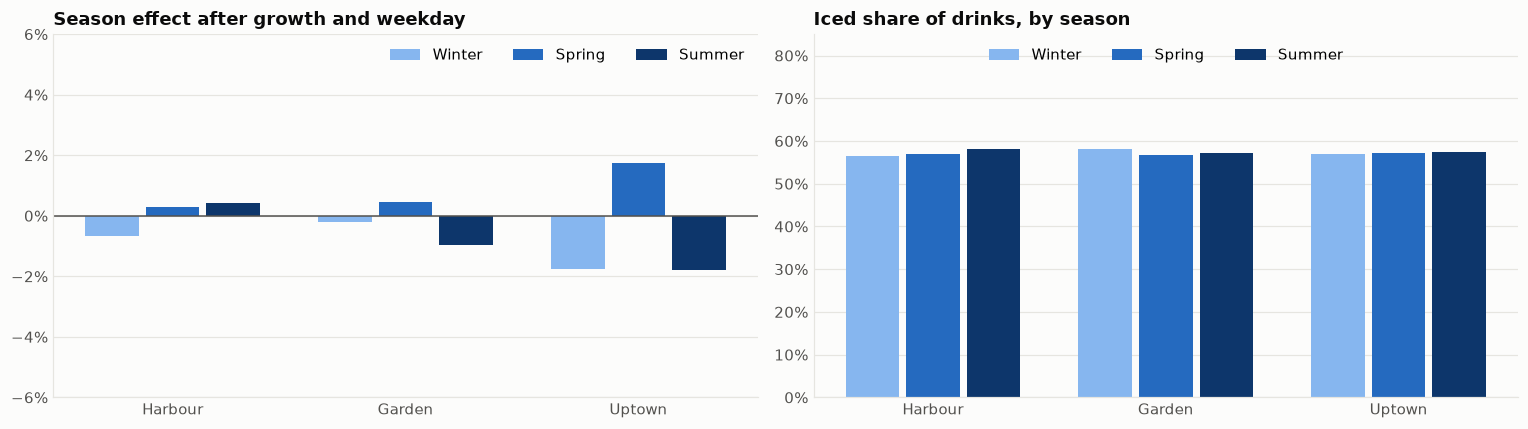

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ax = axes[0]
x = np.arange(len(BRANCHES))
w = 0.26
for i, s in enumerate(SEASONS):
    vals = season_adj[f"{s}: orders vs expected"].values
    ax.bar(x + (i - 1) * w, vals, width=w - 0.03, color=SEASON_COLORS[s], label=s)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(x, BRANCHES)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(-0.06, 0.06)
ax.set_title("Season effect after growth and weekday")
ax.legend(loc="upper right", ncols=3)
ax.grid(axis="x", visible=False)

ax = axes[1]
for i, s in enumerate(SEASONS):
    vals = iced[f"{s}: iced share"].values
    ax.bar(x + (i - 1) * w, vals, width=w - 0.03, color=SEASON_COLORS[s], label=s)
ax.set_xticks(x, BRANCHES)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.85)
ax.set_title("Iced share of drinks, by season")
ax.legend(loc="upper center", ncols=3)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Takeaway:** the three branches behave the same way. No season is more than 2% above or below expected at any branch, no weather correlation is stronger than ±0.13, and the iced share of drinks is 56-58% everywhere in every season.

## 9. Conclusion

**The data shows no weather or season effect at any branch, whether the branches are in the North, the Jabal or Beirut.**

| | Harbour | Garden | Uptown |
|---|---|---|---|
| Season effect after growth and weekday | Within 1% | Within 1% | Within 2% |
| Strongest weather correlation (North) | Rain +0.13 | Wind -0.10 | Rain -0.07 |
| Rainy vs dry days (North) | +1% | 0% | +1% |
| Same tests with Jabal or Beirut weather | No effect | No effect | No effect |
| Iced share of drinks, winter → summer | 56% → 58% | 58% → 57% | 57% → 58% |
| Takeaway, time of day, order value | Unchanged | Unchanged | Unchanged |
| Verdict | No effect | No effect | No effect |

**How to interpret this:**
1. **The dataset is synthetic** and was clearly generated without weather in mind. The flat iced-drink share is the giveaway: no real café in Beirut sells the same share of iced drinks in January as in June. This matches the war and holiday results (`02_war_impact`, `03_holidays`) and the team's pitch: demand here follows the calendar (trend and weekday), not outside events.
2. **For the pitch**, don't propose weather-based actions *from this data*. If you mention the weather, use it as evidence that the data follows a generated pattern, which is why the recommendations rely on its internal structure (prices, costs, customers).
3. **In real café data** you would usually expect: iced drinks rising sharply with temperature, fewer walk-ins on rainy days, more takeaway or delivery when it rains, later evening visits in summer, and seasonal menu opportunities (hot drinks and soups in winter, cold drinks and frozen desserts in summer). Branches can also differ, for example one near the sea or a university reacting more than the others.

To change the seasons (for example astronomical seasons, with winter until Mar 19), the rainy-day threshold or the main weather location, edit `SEASON_OF_MONTH`, `RAINY_MM` or `MAIN_LOCATION` in the first code cell and re-run all cells. To add another town, download its file with the link pattern in the first code cell and add it to `LOCATIONS`.